# Mediation Analysis

This notebook checks whether observable output behavior helps explain prompt-framing effects on pass rate. It focuses on the local-model code and math datasets because those have full extracted-code fields and the strongest model/task variation.

Mediators:
- `log_completion_tokens`: response verbosity
- `result_only`: code-only or final-answer-only compliance
- `log_duration`: latency

The models below use linear probability models with model and base-task fixed effects.

## 1. Setup

Load libraries, find the `results_analysis` folder automatically, and set plotting defaults.

In [1]:
from pathlib import Path
import os
import json
import re
import math

os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib-cache'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.figsize'] = (8, 4.8)

def find_results_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'prompt_templates').is_dir() and (candidate / 'smallmodels').is_dir() and (candidate / 'apimodels').is_dir():
            return candidate
        nested = candidate / '02ScalingPhrase' / 'results_analysis'
        if (nested / 'prompt_templates').is_dir() and (nested / 'smallmodels').is_dir() and (nested / 'apimodels').is_dir():
            return nested
    raise FileNotFoundError('results_analysis root not found')

ROOT = find_results_root()
ROOT

PosixPath('/Users/macos/LearningSpace/ue-courses/Thesis/02ScalingPhrase/results_analysis')

## 2. Load Prompt Metadata

The prompt matrix has 18 variants: 3 tones x 2 role conditions x 3 output formats. Code uses `expert persona`; math uses `developer role`. Both are recoded to a binary `role` vs `no role` variable.

In [2]:
templates = {}
for kind_name, fname in [
    ('code', 'prompt_matrix_prompt_template.09.csv'),
    ('math', 'prompt_matrix_prompt_template.09.math.csv'),
    ('python', 'prompt_matrix_prompt_template.09.csv'),
]:
    t = pd.read_csv(ROOT / 'prompt_templates' / fname)
    tmp = t.rename(columns={
        'ID': 'variant_id',
        'Tone': 'tone',
        'Role framing': 'role_framing',
        'Format': 'format',
    })
    tmp = tmp[['variant_id', 'tone', 'role_framing', 'format']].copy()
    tmp['kind'] = kind_name
    tmp['variant_id'] = tmp['variant_id'].astype(str)
    tmp['role_binary'] = np.where(tmp['role_framing'].str.lower().eq('no role'), 'no role', 'role')
    templates[kind_name] = tmp

meta = pd.concat(templates.values(), ignore_index=True)
display(meta.groupby(['kind', 'tone', 'role_binary', 'format']).size().rename('variants').reset_index().head(12))
print(f'Total metadata rows: {len(meta)}')

,kind,tone,role_binary,format,variants
0,code,aggressive,no role,json,1
1,code,aggressive,no role,plaintext,1
2,code,aggressive,no role,xml,1
3,code,aggressive,role,json,1
4,code,aggressive,role,plaintext,1
5,code,aggressive,role,xml,1
6,code,neutral,no role,json,1
7,code,neutral,no role,plaintext,1
8,code,neutral,no role,xml,1
9,code,neutral,role,json,1


Total metadata rows: 54


## 3. Load Result Files

Load all local and API result files. The mediation analysis below focuses on local models, but API rows are loaded for package-level integrity checks.

In [3]:
def read_jsonl(path):
    rows = []
    with path.open(encoding='utf-8') as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))
    return rows

def safe_len(value):
    if isinstance(value, str):
        return len(value)
    return 0 if pd.isna(value) else len(str(value))

small_rows = []
for path in sorted((ROOT / 'smallmodels').glob('*.jsonl')):
    kind = 'math' if path.name.endswith('.math.jsonl') else 'code'
    model = path.name.replace('.math.jsonl', '').replace('.jsonl', '')
    for row in read_jsonl(path):
        task_id = str(row.get('task_id'))
        match = re.search(r'_(\d+)$', task_id)
        row = dict(row)
        row['variant_id'] = match.group(1) if match else ''
        row['base_task_id'] = re.sub(r'_\d+$', '', task_id)
        row['kind'] = kind
        row['model_slug'] = model
        row['modeltype'] = 'local'
        small_rows.append(row)

small_df = pd.DataFrame(small_rows).merge(meta, on=['kind', 'variant_id'], how='left')

api_rows = []
for path in sorted((ROOT / 'apimodels').glob('*.jsonl')):
    kind = 'python' if path.name.endswith('.python.jsonl') else 'math'
    model = path.name.replace('.python.jsonl', '').replace('.math.jsonl', '')
    for row in read_jsonl(path):
        row = dict(row)
        row['kind'] = kind
        row['model_slug'] = model
        row['variant_id'] = str(row.get('category_id'))
        row['modeltype'] = 'api'
        usage = row.get('raw_usage') or {}
        row['completion_tokens'] = usage.get('completion_tokens', 0)
        api_rows.append(row)

api_df = pd.DataFrame(api_rows).merge(meta, on=['kind', 'variant_id'], how='left')

for df in [small_df, api_df]:
    for col in ['duration_seconds', 'prompt_tokens', 'completion_tokens']:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    df['passed'] = df['passed'].astype(bool)

small_df['model_short'] = small_df['model_slug'].str.replace('_1_50', '', regex=False)
api_df['model_short'] = api_df['model_slug']

print(f'Local rows: {len(small_df):,}')
print(f'API rows: {len(api_df):,}')
print(f'Total rows: {len(small_df) + len(api_df):,}')

Local rows: 10,800
API rows: 3,600
Total rows: 14,400


## 4. Data Integrity Snapshot

Confirm row counts, prompt metadata joins, and empty responses before modeling.

In [4]:
def integrity_table(df, label):
    grouped = df.groupby(['modeltype', 'kind', 'model_short']).agg(
        rows=('passed', 'size'),
        passed=('passed', 'sum'),
        pass_rate=('passed', 'mean'),
        prompt_join_gaps=('tone', lambda s: s.isna().sum()),
        empty_responses=('response_text', lambda s: s.fillna('').str.strip().eq('').sum()),
    ).reset_index()
    grouped['dataset'] = label
    grouped['pass_rate_pct'] = (100 * grouped['pass_rate']).round(1)
    return grouped[['dataset', 'modeltype', 'kind', 'model_short', 'rows', 'passed', 'pass_rate_pct', 'prompt_join_gaps', 'empty_responses']]

integrity = pd.concat([integrity_table(small_df, 'smallmodels'), integrity_table(api_df, 'apimodels')], ignore_index=True)
display(integrity)

summary = integrity.groupby(['dataset', 'kind']).agg(
    files=('model_short', 'count'),
    rows=('rows', 'sum'),
    empty_responses=('empty_responses', 'sum'),
    prompt_join_gaps=('prompt_join_gaps', 'sum'),
).reset_index()
display(summary)

,dataset,modeltype,kind,model_short,rows,passed,pass_rate_pct,prompt_join_gaps,empty_responses
0,smallmodels,local,code,deepseek-coder-6.7b-instruct,900,10,1.1,0,0
1,smallmodels,local,code,gemma2-9b,900,102,11.3,0,0
2,smallmodels,local,code,llama3.1-8b,900,52,5.8,0,0
3,smallmodels,local,code,mistral-7b-instruct,900,4,0.4,0,0
4,smallmodels,local,code,nemotron-3-nano-4b,900,205,22.8,0,14
5,smallmodels,local,code,qwen2.5-7b,900,119,13.2,0,0
6,smallmodels,local,math,deepseek-coder-6.7b-instruct,900,51,5.7,0,0
7,smallmodels,local,math,gemma2-9b,900,137,15.2,0,0
8,smallmodels,local,math,llama3.1-8b,900,389,43.2,0,0
9,smallmodels,local,math,mistral-7b-instruct,900,69,7.7,0,0


,dataset,kind,files,rows,empty_responses,prompt_join_gaps
0,apimodels,math,2,1800,0,0
1,apimodels,python,2,1800,0,0
2,smallmodels,code,6,5400,14,0
3,smallmodels,math,6,5400,0,0


## 5. Construct Behavioral Mediators

For local code tasks, `result_only` means extracted code exists and extra explanation is under 15% of the response. For local math tasks, `result_only` means the response is shorter than 50 characters, approximating final-answer-only behavior.

In [5]:
small_df['response_chars'] = small_df['response_text'].map(safe_len)
small_df['code_chars'] = small_df['extracted_code'].map(safe_len) if 'extracted_code' in small_df else 0
small_df['extra_text_chars'] = (small_df['response_chars'] - small_df['code_chars']).clip(lower=0)
small_df['extra_text_ratio'] = np.where(
    small_df['response_chars'] > 0,
    small_df['extra_text_chars'] / small_df['response_chars'],
    np.nan,
)
small_df['has_code'] = (small_df['code_chars'] > 0).astype(int)
small_df['result_only'] = 0
code_mask = small_df['kind'].eq('code')
math_mask = small_df['kind'].eq('math')
small_df.loc[code_mask, 'result_only'] = (
    (small_df.loc[code_mask, 'has_code'] == 1)
    & (small_df.loc[code_mask, 'extra_text_ratio'] < 0.15)
).astype(int)
small_df.loc[math_mask, 'result_only'] = (small_df.loc[math_mask, 'response_chars'] < 50).astype(int)

small_df['log_completion_tokens'] = np.log1p(small_df['completion_tokens'])
small_df['log_duration'] = np.log1p(small_df['duration_seconds'])
small_df['passed_float'] = small_df['passed'].astype(float)

for col, expr in {
    'tone_aggressive': small_df['tone'].eq('aggressive'),
    'tone_polite': small_df['tone'].eq('polite'),
    'role_vs_no_role': small_df['role_binary'].eq('role'),
    'format_json': small_df['format'].eq('json'),
    'format_xml': small_df['format'].eq('xml'),
}.items():
    small_df[col] = expr.astype(float)

prompt_cols = ['tone_aggressive', 'tone_polite', 'role_vs_no_role', 'format_json', 'format_xml']
mediator_cols = ['log_completion_tokens', 'result_only', 'log_duration']
fe_cols = ['model_short', 'base_task_id']

mediator_summary = small_df.groupby(['kind', 'model_short']).agg(
    pass_rate=('passed', 'mean'),
    mean_tokens=('completion_tokens', 'mean'),
    median_duration=('duration_seconds', 'median'),
    result_only_rate=('result_only', 'mean'),
).reset_index()
mediator_summary[['pass_rate', 'result_only_rate']] = mediator_summary[['pass_rate', 'result_only_rate']] * 100
display(mediator_summary.round(1))

,kind,model_short,pass_rate,mean_tokens,median_duration,result_only_rate
0,code,deepseek-coder-6.7b-instruct,1.1,491.1,9.0,0.8
1,code,gemma2-9b,11.3,175.2,5.5,98.8
2,code,llama3.1-8b,5.8,393.9,11.2,100.0
3,code,mistral-7b-instruct,0.4,366.2,9.1,44.9
4,code,nemotron-3-nano-4b,22.8,1646.1,17.8,92.9
5,code,qwen2.5-7b,13.2,316.0,8.8,99.9
6,math,deepseek-coder-6.7b-instruct,5.7,287.1,5.3,0.0
7,math,gemma2-9b,15.2,6.1,0.8,99.9
8,math,llama3.1-8b,43.2,273.6,5.1,6.6
9,math,mistral-7b-instruct,7.7,78.7,0.9,46.3


## 6. Result-Only Compliance By Model

This chart shows why result-only compliance behaves differently across task kinds. Some models are almost always result-only; others are almost never result-only.

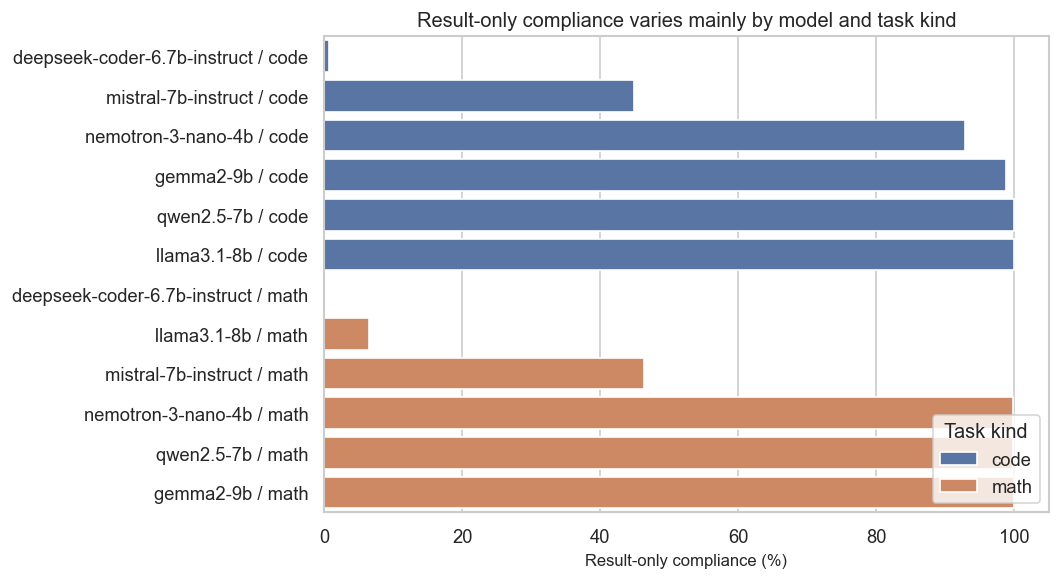

In [6]:
plot_df = mediator_summary.copy()
plot_df['label'] = plot_df['model_short'] + ' / ' + plot_df['kind']
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_df.sort_values(['kind', 'result_only_rate']), x='result_only_rate', y='label', hue='kind', dodge=False, ax=ax)
ax.set_xlabel('Result-only compliance (%)')
ax.set_ylabel('')
ax.set_xlim(0, 105)
ax.legend(title='Task kind', loc='lower right')
ax.set_title('Result-only compliance varies mainly by model and task kind')
plt.tight_layout()
plt.show()

## 7. Fixed-Effect LPM Helper

The helper below estimates a linear probability model with dummy fixed effects for model and base task. Coefficients on pass-rate outcomes are reported in percentage points.

In [7]:
def fit_lpm(data, outcome_col, regressor_cols, fe_cols):
    needed = [outcome_col] + regressor_cols + fe_cols
    work = data[needed].replace([np.inf, -np.inf], np.nan).dropna()
    if work.empty:
        return {}

    y = work[outcome_col].astype(float).to_numpy()
    X = work[regressor_cols].astype(float).copy()
    for col in fe_cols:
        dummies = pd.get_dummies(work[col].astype(str), prefix=col, drop_first=True, dtype=float)
        X = pd.concat([X, dummies], axis=1)
    X.insert(0, 'Intercept', 1.0)

    Xv = X.to_numpy(dtype=float)
    beta, *_ = np.linalg.lstsq(Xv, y, rcond=None)
    pred = Xv @ beta
    resid = y - pred
    dof = max(len(y) - Xv.shape[1], 1)
    sigma2 = float((resid @ resid) / dof)
    xtx_inv = np.linalg.pinv(Xv.T @ Xv)
    se = np.sqrt(np.clip(np.diag(xtx_inv) * sigma2, 0, np.inf))

    result = {}
    for term, b, s in zip(X.columns, beta, se):
        if term in regressor_cols:
            p = math.erfc(abs(b / s) / math.sqrt(2)) if s > 0 else 1.0
            result[term] = {
                'coef': b,
                'coef_pp': 100 * b,
                'std_err': s,
                'std_err_pp': 100 * s,
                'p_value': p,
                'nobs': len(y),
            }
    return result

def lpm_table(data, outcome_col, regressor_cols=prompt_cols, fe_cols=fe_cols):
    res = fit_lpm(data, outcome_col, regressor_cols, fe_cols)
    rows = []
    for term in regressor_cols:
        if term in res:
            rows.append({
                'factor': term,
                'coef_pp': res[term]['coef_pp'],
                'p_value': res[term]['p_value'],
                'significant_0_05': res[term]['p_value'] < 0.05,
                'nobs': res[term]['nobs'],
            })
    return pd.DataFrame(rows)

## 8. Step 1: Prompt Factors Affect Output Behavior

Before claiming mediation, first check whether prompt factors change the mediators themselves.

In [8]:
step1_rows = []
for kind_name in ['code', 'math']:
    sub = small_df[small_df.kind.eq(kind_name)]
    for mediator_name, mediator_col in [
        ('log(tokens)', 'log_completion_tokens'),
        ('result_only', 'result_only'),
        ('log(duration)', 'log_duration'),
    ]:
        tab = lpm_table(sub, mediator_col)
        tab['kind'] = kind_name
        tab['mediator'] = mediator_name
        step1_rows.append(tab)

step1 = pd.concat(step1_rows, ignore_index=True)
step1_display = step1[['kind', 'mediator', 'factor', 'coef_pp', 'p_value', 'significant_0_05']].copy()
display(step1_display.round({'coef_pp': 2, 'p_value': 4}))

,kind,mediator,factor,coef_pp,p_value,significant_0_05
0,code,log(tokens),tone_aggressive,0.55,0.6784,False
1,code,log(tokens),tone_polite,12.40,0.0000,True
2,code,log(tokens),role_vs_no_role,3.17,0.0034,True
3,code,log(tokens),format_json,-3.46,0.0091,True
4,code,log(tokens),format_xml,-4.10,0.0020,True
5,code,result_only,tone_aggressive,-1.39,0.0691,False
6,code,result_only,tone_polite,-7.00,0.0000,True
7,code,result_only,role_vs_no_role,-1.15,0.0657,False
8,code,result_only,format_json,4.61,0.0000,True
9,code,result_only,format_xml,7.33,0.0000,True


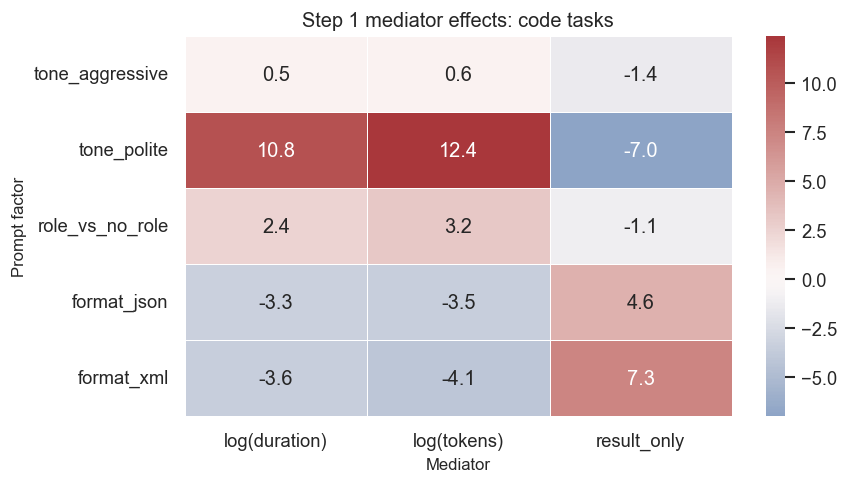

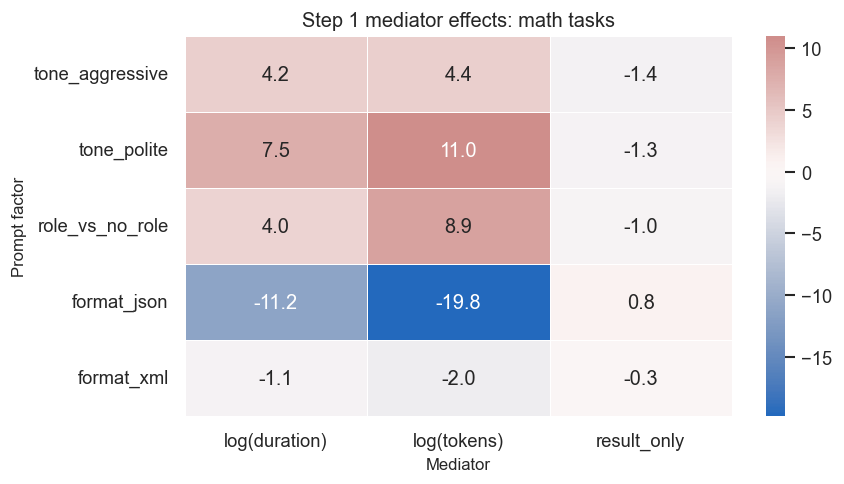

In [9]:
for kind_name in ['code', 'math']:
    heat = step1[step1.kind.eq(kind_name)].pivot(index='factor', columns='mediator', values='coef_pp').loc[prompt_cols]
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    sns.heatmap(heat, annot=True, fmt='.1f', cmap='vlag', center=0, linewidths=.5, ax=ax)
    ax.set_title(f'Step 1 mediator effects: {kind_name} tasks')
    ax.set_xlabel('Mediator')
    ax.set_ylabel('Prompt factor')
    plt.tight_layout()
    plt.show()

## 9. Step 2: Mediation Decomposition

Compare the total prompt-factor coefficient with versions that control for each mediator. The difference between total and controlled coefficient is a descriptive mediation estimate, not a causal proof.

In [10]:
specs = {
    '+tokens': ['log_completion_tokens'],
    '+res_only': ['result_only'],
    '+duration': ['log_duration'],
    '+all3': ['log_completion_tokens', 'result_only', 'log_duration'],
}

def mediation_decomposition(data):
    total_res = fit_lpm(data, 'passed_float', prompt_cols, fe_cols)
    rows = []
    for term in prompt_cols:
        if term not in total_res:
            continue
        total_coef = total_res[term]['coef']
        row = {
            'factor': term,
            'total_pp': total_res[term]['coef_pp'],
            'total_p': total_res[term]['p_value'],
        }
        for spec_name, controls in specs.items():
            res = fit_lpm(data, 'passed_float', prompt_cols + controls, fe_cols)
            if term in res:
                controlled = res[term]['coef']
                indirect = total_coef - controlled
                prop = indirect / total_coef if abs(total_coef) > 1e-10 else np.nan
                row[f'{spec_name}_pp'] = res[term]['coef_pp']
                row[f'{spec_name}_prop'] = prop
        rows.append(row)
    return pd.DataFrame(rows)

med_tables = {}
for kind_name in ['code', 'math']:
    med_tables[kind_name] = mediation_decomposition(small_df[small_df.kind.eq(kind_name)].copy())
    display(Markdown(f'### {kind_name.title()} tasks'))
    display(med_tables[kind_name].round(4))

### Code tasks

,factor,total_pp,total_p,+tokens_pp,+tokens_prop,+res_only_pp,+res_only_prop,+duration_pp,+duration_prop,+all3_pp,+all3_prop
0,tone_aggressive,-0.0000,1.0000,0.0368,NaN,-0.0245,NaN,0.0443,NaN,-0.0120,NaN
1,tone_polite,-0.5000,0.5443,0.3285,1.6569,-0.6236,-0.2472,0.4126,1.8252,0.1708,1.3417
2,role_vs_no_role,-1.0370,0.1235,-0.8252,0.2042,-1.0573,-0.0195,-0.8327,0.1970,-0.8715,0.1596
3,format_json,0.1667,0.8398,-0.0646,1.3874,0.2481,-0.4885,-0.1153,1.6920,0.0617,0.6298
4,format_xml,0.8333,0.3122,0.5594,0.3287,0.9628,-0.1554,0.5302,0.3637,0.8247,0.0103


### Math tasks

,factor,total_pp,total_p,+tokens_pp,+tokens_prop,+res_only_pp,+res_only_prop,+duration_pp,+duration_prop,+all3_pp,+all3_prop
0,tone_aggressive,0.9444,0.3697,0.7102,0.2480,0.8783,0.0701,0.7163,0.2416,1.4455,-0.5305
1,tone_polite,1.6667,0.1134,1.0817,0.3510,1.6058,0.0365,1.2631,0.2421,1.5115,0.0931
2,role_vs_no_role,2.1852,0.0110,1.7129,0.2161,2.1375,0.0218,1.9712,0.0979,1.3836,0.3668
3,format_json,-4.1667,0.0001,-3.1112,0.2533,-4.1296,0.0089,-3.5665,0.1440,-2.8351,0.3196
4,format_xml,-2.2222,0.0348,-2.1176,0.0471,-2.2355,-0.0060,-2.1608,0.0276,-2.0357,0.0840


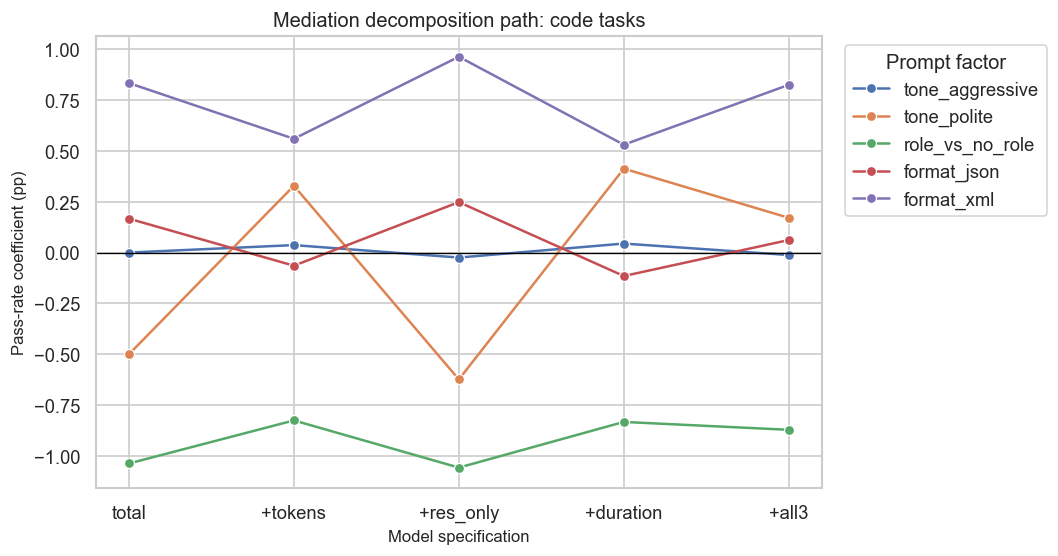

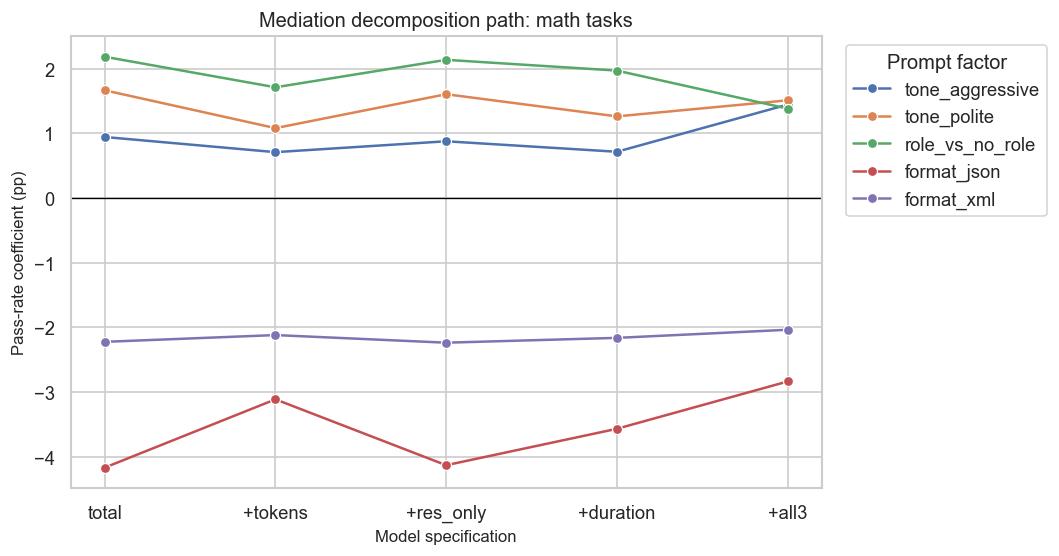

In [11]:
plot_rows = []
for kind_name, tab in med_tables.items():
    for _, row in tab.iterrows():
        for spec in ['total', '+tokens', '+res_only', '+duration', '+all3']:
            col = 'total_pp' if spec == 'total' else f'{spec}_pp'
            plot_rows.append({'kind': kind_name, 'factor': row['factor'], 'spec': spec, 'coef_pp': row[col]})
plot_med = pd.DataFrame(plot_rows)

for kind_name in ['code', 'math']:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    sns.lineplot(data=plot_med[plot_med.kind.eq(kind_name)], x='spec', y='coef_pp', hue='factor', marker='o', ax=ax)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set_title(f'Mediation decomposition path: {kind_name} tasks')
    ax.set_xlabel('Model specification')
    ax.set_ylabel('Pass-rate coefficient (pp)')
    ax.legend(title='Prompt factor', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

## 10. Tone-Specific Detail

The original pilot focused heavily on tone. This table keeps the tone story visible while the rest of the notebook checks role and format too.

,kind,factor,total_pp,controlled_all3_pp,indirect_all3_pp,prop_all3
0,code,tone_aggressive,-0.0000,-0.0120,0.0120,NaN
1,code,tone_polite,-0.5000,0.1708,-0.6708,1.3417
2,math,tone_aggressive,0.9444,1.4455,-0.5010,-0.5305
3,math,tone_polite,1.6667,1.5115,0.1551,0.0931


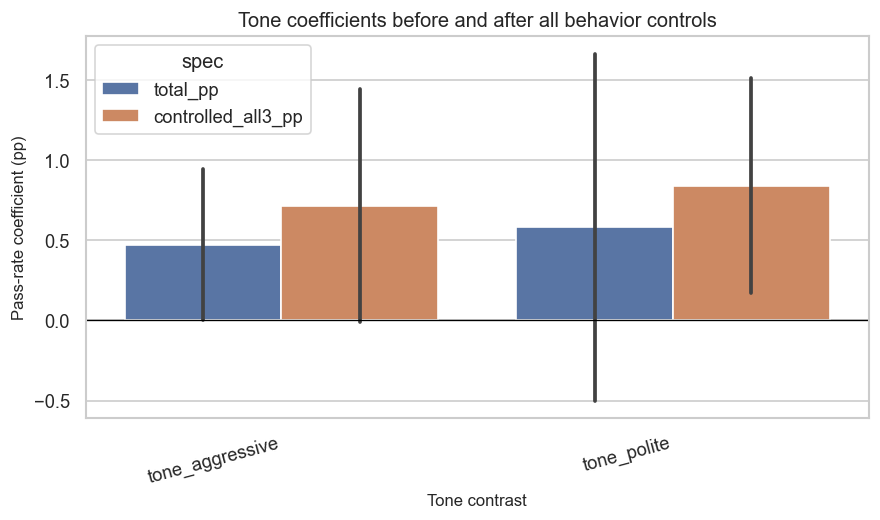

In [12]:
tone_rows = []
for kind_name, tab in med_tables.items():
    for factor in ['tone_aggressive', 'tone_polite']:
        row = tab[tab.factor.eq(factor)].iloc[0]
        tone_rows.append({
            'kind': kind_name,
            'factor': factor,
            'total_pp': row['total_pp'],
            'controlled_all3_pp': row['+all3_pp'],
            'indirect_all3_pp': row['total_pp'] - row['+all3_pp'],
            'prop_all3': row['+all3_prop'],
        })
tone_detail = pd.DataFrame(tone_rows)
display(tone_detail.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
tone_plot = tone_detail.melt(id_vars=['kind', 'factor'], value_vars=['total_pp', 'controlled_all3_pp'], var_name='spec', value_name='coef_pp')
sns.barplot(data=tone_plot, x='factor', y='coef_pp', hue='spec', ax=ax)
ax.axhline(0, color='black', linewidth=.8)
ax.set_title('Tone coefficients before and after all behavior controls')
ax.set_xlabel('Tone contrast')
ax.set_ylabel('Pass-rate coefficient (pp)')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

## 11. Descriptive Behavior By Tone And Model

These descriptive bars are not fixed-effect estimates. They are useful for seeing which models drive the average behavior patterns.

,kind,model_short,tone,n,pass_rate,mean_tokens,result_only_rate,median_duration,pass_rate_pct,result_only_pct
0,code,deepseek-coder-6.7b-instruct,aggressive,300,0.023333,468.0,0.003333,8.55,2.3,0.3
1,code,deepseek-coder-6.7b-instruct,neutral,300,0.003333,496.1,0.013333,8.84,0.3,1.3
2,code,deepseek-coder-6.7b-instruct,polite,300,0.006667,509.1,0.006667,9.68,0.7,0.7
3,code,gemma2-9b,aggressive,300,0.100000,176.0,0.993333,5.52,10.0,99.3
4,code,gemma2-9b,neutral,300,0.120000,168.4,0.973333,5.31,12.0,97.3
5,code,gemma2-9b,polite,300,0.120000,181.3,0.996667,5.68,12.0,99.7
6,code,llama3.1-8b,aggressive,300,0.053333,383.4,1.000000,10.42,5.3,100.0
7,code,llama3.1-8b,neutral,300,0.073333,368.9,1.000000,10.17,7.3,100.0
8,code,llama3.1-8b,polite,300,0.046667,429.5,1.000000,12.55,4.7,100.0
9,code,mistral-7b-instruct,aggressive,300,0.010000,329.1,0.540000,7.90,1.0,54.0


/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_36905/1669219958.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


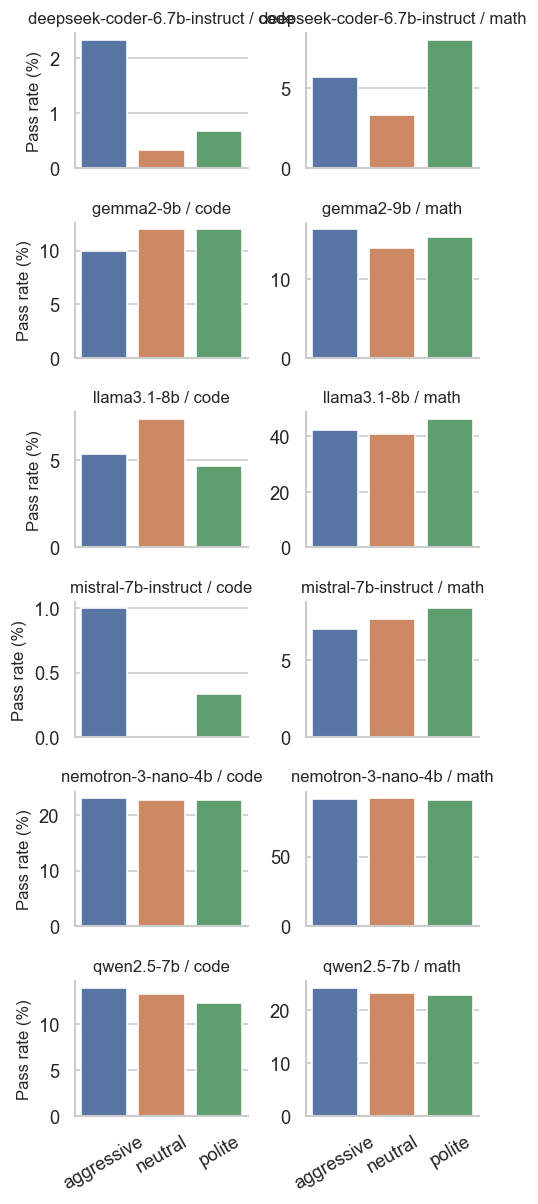

/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_36905/1669219958.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


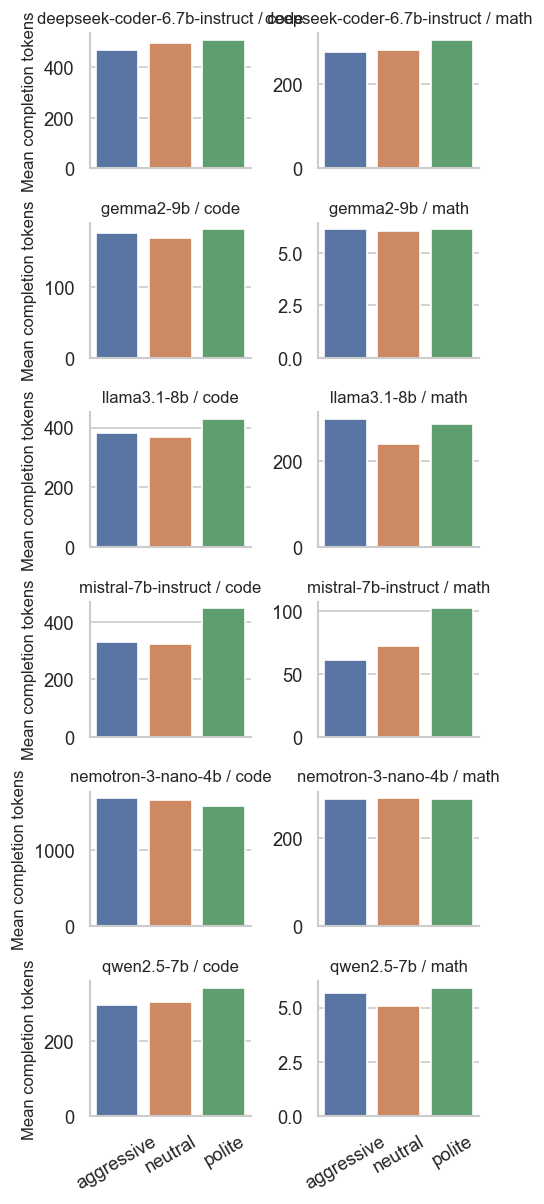

/Users/macos/.pyenv/versions/3.11.10/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_36905/1669219958.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


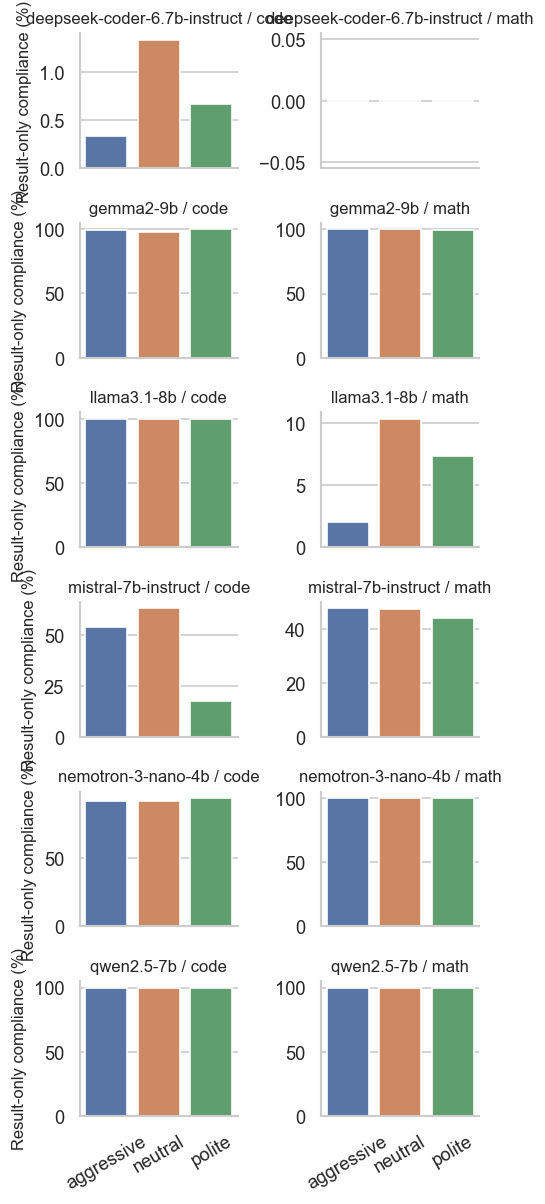

In [13]:
desc = small_df.groupby(['kind', 'model_short', 'tone']).agg(
    n=('passed', 'size'),
    pass_rate=('passed', 'mean'),
    mean_tokens=('completion_tokens', 'mean'),
    result_only_rate=('result_only', 'mean'),
    median_duration=('duration_seconds', 'median'),
).reset_index()
desc['pass_rate_pct'] = 100 * desc['pass_rate']
desc['result_only_pct'] = 100 * desc['result_only_rate']

display(desc.round({'pass_rate_pct': 1, 'mean_tokens': 1, 'result_only_pct': 1, 'median_duration': 2}).head(18))

for metric, label in [('pass_rate_pct', 'Pass rate (%)'), ('mean_tokens', 'Mean completion tokens'), ('result_only_pct', 'Result-only compliance (%)')]:
    g = sns.catplot(
        data=desc,
        kind='bar',
        x='tone',
        y=metric,
        hue='tone',
        col='kind',
        row='model_short',
        sharey=False,
        height=1.7,
        aspect=1.25,
        legend=False,
    )
    g.set_axis_labels('', label)
    g.set_titles('{row_name} / {col_name}')
    for ax in g.axes.flat:
        ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()

## 12. Interpretation Notes

Key readout:
- Prompt factors clearly change output behavior, especially verbosity, latency, and result-only compliance.
- For local code tasks, polite tone is behavior-sensitive: controlling for verbosity and compliance can flip its small pooled coefficient.
- For local math tasks, JSON format has a negative pass-rate effect and a meaningful part is associated with reduced verbosity.
- These are fixed-effect linear probability models and should be interpreted as exploratory evidence, not causal proof.